# 問題說明


使用 50 家新創公司的資料，建立利潤預測模型。


# 匯入套件


In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from statsmodels.graphics.regressionplots import influence_plot
import statsmodels.formula.api as smf
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 載入資料集


In [ ]:
from pathlib import Path

# 支援從筆記本所在資料夾或專案根目錄執行。
data_paths = [
    Path("50_Startups.csv"),
    Path("src/ai_infosec_dic2/50-startup-linearregression/50_Startups.csv"),
]
data_path = next((path for path in data_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("50_Startups.csv not found; run from the notebook folder or project root.")
startups = pd.read_csv(data_path)

In [3]:
startups.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


使用 pandas 的 `head()` 方法預覽資料；預設會顯示前 5 筆。


# 認識資料


In [4]:
startups.shape

(50, 5)

In [5]:
startups.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='str')

### 觀察結果


1. 資料集包含 50 家新創公司，共有 5 個欄位：研發支出（`R&D Spend`）、行政支出（`Administration`）、行銷支出（`Marketing Spend`）、所在州別（`State`）及利潤（`Profit`）。
2. 前 3 個欄位分別記錄各公司的研發、行政及行銷支出。
3. `State` 表示公司所在的州，`Profit` 表示公司的利潤。


In [6]:
startups.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.1 KB


### 觀察結果


1. 研發支出、行政支出、行銷支出及利潤為浮點數資料；州別為文字資料，實際型別可參考上方的 `info()` 輸出。
2. 全部 50 筆資料的各欄位皆有值，沒有缺失值。


In [7]:
startups[startups.duplicated()]

,R&D Spend,Administration,Marketing Spend,State,Profit


本資料集沒有重複資料。若出現重複資料，應先確認原因，再決定是否刪除。


# 敘述統計


In [8]:
startups.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


### 觀察結果


1. 各數值欄位的平均數與中位數（第 50 百分位數）差距不大。
2. 行銷支出的第 75 百分位數約為 299,469，最大值約為 471,784，兩者有明顯差距。
3. 這些統計量可作為了解資料分布的起點，但不能單憑平均數或最大值判定是否有離群值，以下將使用箱型圖進一步觀察。


# 認識目標變數


本分析要預測新創公司的利潤，因此目標變數為 `Profit`。


In [9]:
startups['Profit'].unique()

array([192261.83, 191792.06, 191050.39, 182901.99, 166187.94, 156991.12,
       156122.51, 155752.6 , 152211.77, 149759.96, 146121.95, 144259.4 ,
       141585.52, 134307.35, 132602.65, 129917.04, 126992.93, 125370.37,
       124266.9 , 122776.86, 118474.03, 111313.02, 110352.25, 108733.99,
       108552.04, 107404.34, 105733.54, 105008.31, 103282.38, 101004.64,
        99937.59,  97483.56,  97427.84,  96778.92,  96712.8 ,  96479.51,
        90708.19,  89949.14,  81229.06,  81005.76,  78239.91,  77798.83,
        71498.49,  69758.98,  65200.33,  64926.08,  49490.75,  42559.73,
        35673.41,  14681.4 ])

### 觀察結果


`Profit` 是連續型的數值變數。


In [10]:
startups['Profit'].value_counts()

Profit
192261.83    1
191792.06    1
191050.39    1
182901.99    1
166187.94    1
156991.12    1
156122.51    1
155752.60    1
152211.77    1
149759.96    1
146121.95    1
144259.40    1
141585.52    1
134307.35    1
132602.65    1
129917.04    1
126992.93    1
125370.37    1
124266.90    1
122776.86    1
118474.03    1
111313.02    1
110352.25    1
108733.99    1
108552.04    1
107404.34    1
105733.54    1
105008.31    1
103282.38    1
101004.64    1
99937.59     1
97483.56     1
97427.84     1
96778.92     1
96712.80     1
96479.51     1
90708.19     1
89949.14     1
81229.06     1
81005.76     1
78239.91     1
77798.83     1
71498.49     1
69758.98     1
65200.33     1
64926.08     1
49490.75     1
42559.73     1
35673.41     1
14681.40     1
Name: count, dtype: int64

### 觀察結果


每個利潤值都只出現一次，表示 `Profit` 欄位沒有重複值；整筆資料是否重複，則以上方的 `duplicated()` 結果為準。


# 資料視覺化


使用箱型圖進行單一變數分析，觀察資料分布與可能的離群值。


<Axes: ylabel='R&D Spend'>

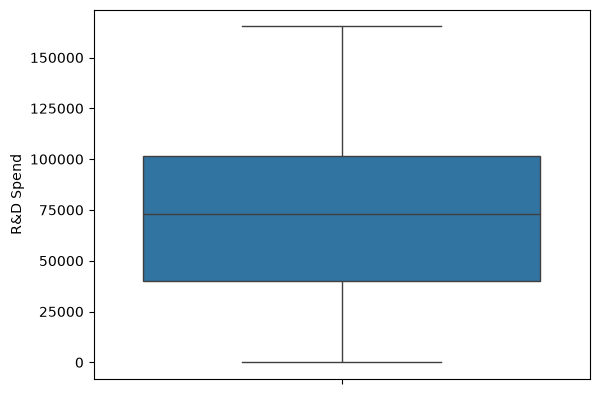

In [11]:
sn.boxplot(startups['R&D Spend'])

### 觀察結果


1. 研發支出的箱型圖沒有標示出離群值。
2. 中位數線接近箱體中央，表示箱體內的分布較對稱；整體是否偏斜仍需搭配其他圖表判斷。


<Axes: ylabel='Administration'>

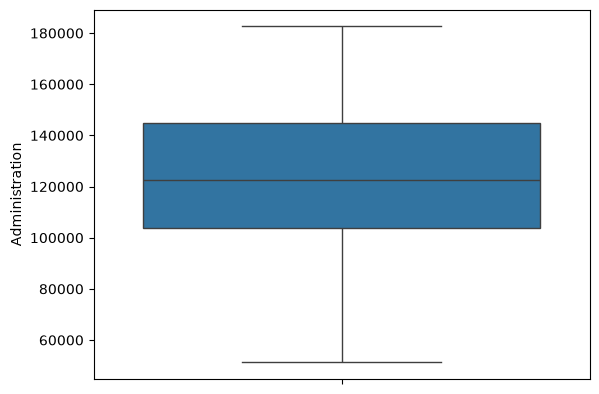

In [12]:
sn.boxplot(startups['Administration'])

### 觀察結果


1. 行政支出的箱型圖沒有標示出離群值。
2. 中位數線偏離箱體中央，表示箱體內的分布並非完全對稱。


<Axes: ylabel='Marketing Spend'>

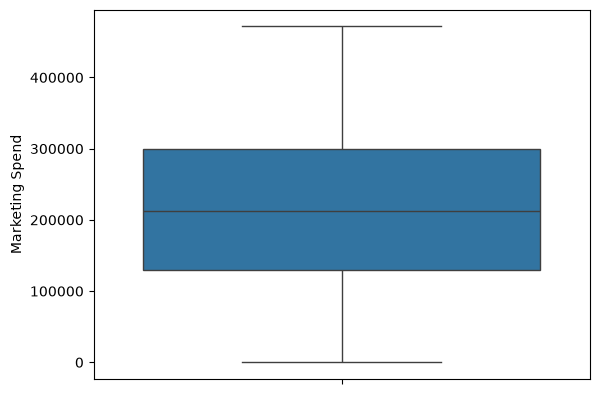

In [13]:
sn.boxplot(startups['Marketing Spend'])

### 觀察結果


1. 行銷支出的箱型圖沒有標示出離群值。
2. 中位數線接近箱體中央，表示箱體內的分布較對稱；這不代表整體分布一定沒有偏斜。


<Axes: ylabel='Profit'>

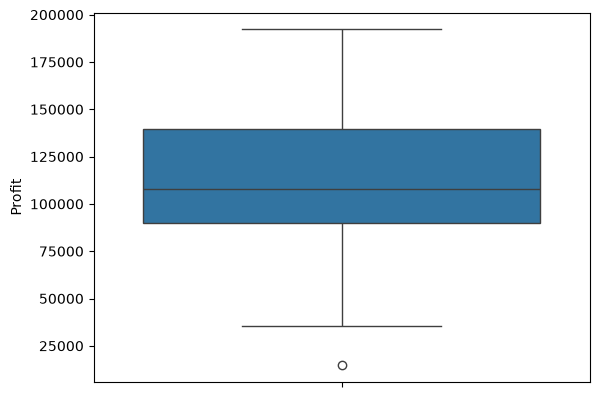

In [14]:
sn.boxplot(startups['Profit'])

### 觀察結果


1. 利潤欄位有一個低於 25,000 的離群值，代表其中一家公司的利潤明顯偏低。
2. 中位數線偏向箱體上方，且低值端有離群值；偏斜方向應搭配直方圖與尾端分布判讀，不能僅依中位數線的位置認定為右偏。


### 分布圖


使用直方圖與核密度估計曲線，觀察資料的分布形狀、主要集中區間及偏斜情形。


<Axes: xlabel='R&D Spend', ylabel='Density'>

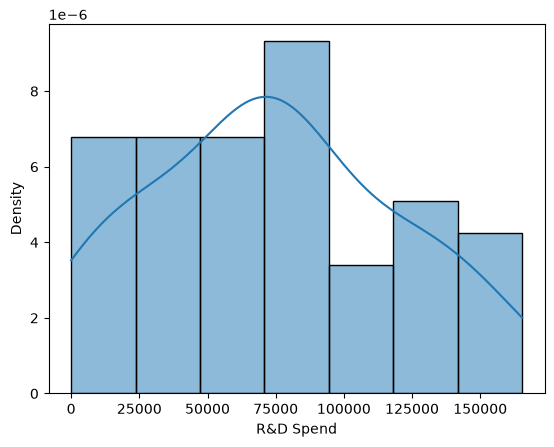

In [15]:
sn.histplot(startups['R&D Spend'], kde=True, stat="density")


<Axes: xlabel='Administration', ylabel='Density'>

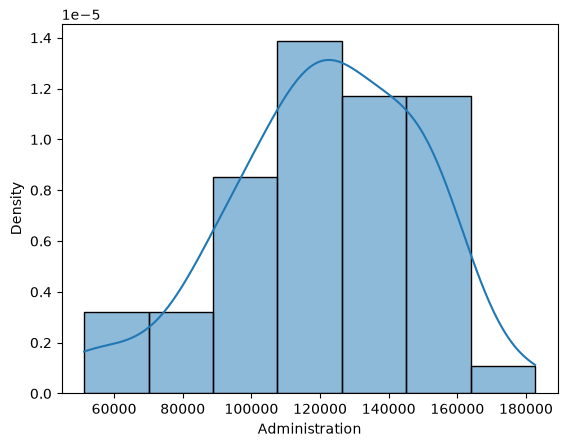

In [16]:
sn.histplot(startups['Administration'], kde=True, stat="density")


<Axes: xlabel='Marketing Spend', ylabel='Density'>

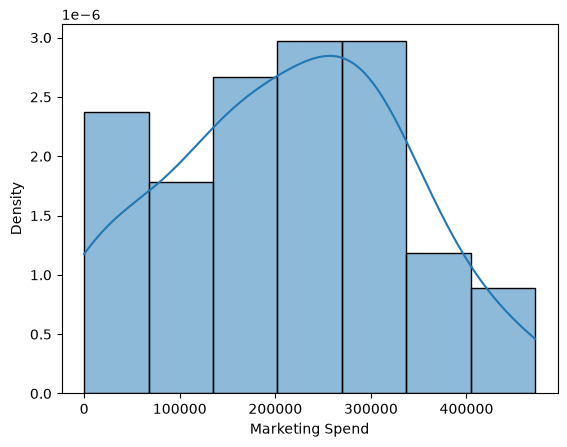

In [17]:
sn.histplot(startups['Marketing Spend'], kde=True, stat="density")


<Axes: xlabel='Profit', ylabel='Density'>

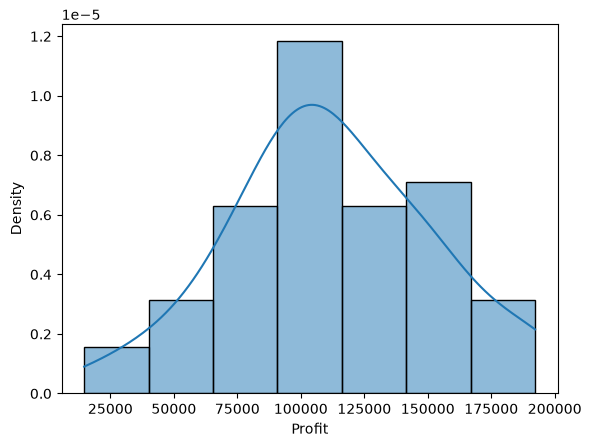

In [18]:
sn.histplot(startups['Profit'], kde=True, stat="density")


### 成對關係圖


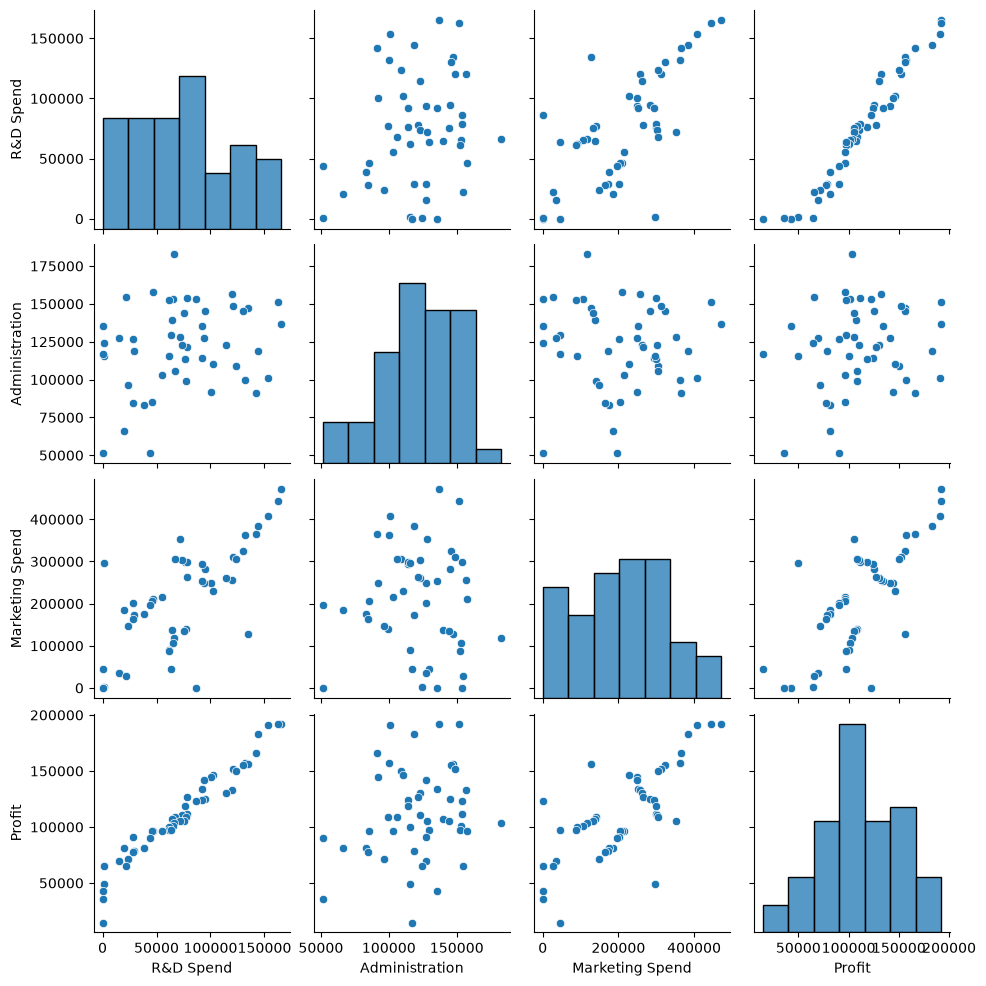

In [19]:
sn.pairplot(startups)

### 觀察結果


1. 研發支出較高的公司通常也有較高的利潤，兩者呈正相關。
2. 研發支出與行銷支出也呈正相關。
3. 其他欄位之間的關係較難直接從圖中判斷，以下將搭配熱圖與相關係數觀察。


### 熱圖


熱圖使用顏色呈現數值差異。以下先用它檢查缺失值，之後再呈現各欄位之間的相關係數。


<Axes: >

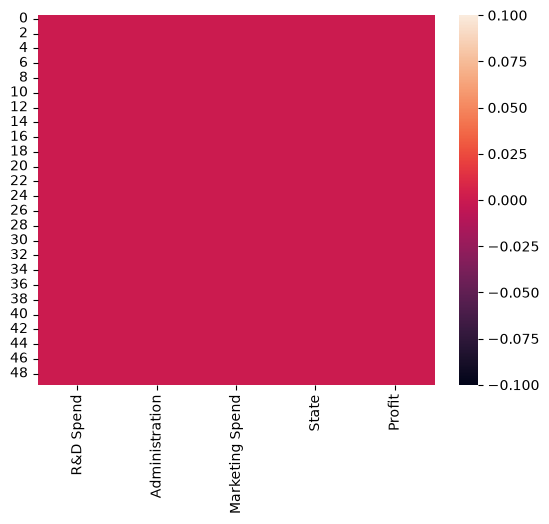

In [20]:
sn.heatmap(startups.isnull())

### 觀察結果


資料集中沒有缺失值，因此圖中沒有代表缺失值的不同色塊。


也可以使用 `isna()` 方法，搭配 `sum()` 統計各欄位的缺失值數量。


In [21]:
startups.isna().sum()

R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

# 相關性分析


相關係數矩陣用來整理各變數之間線性關係的方向與強度，協助了解資料；相關性本身不代表因果關係。


`State` 是沒有大小順序的類別變數，不能直接將州名帶入數值相關係數計算。以下先將州別轉換為獨熱編碼，再觀察各州別指標與其他欄位的相關性。


In [22]:
startups['State'].describe()

count           50
unique           3
top       New York
freq            17
Name: State, dtype: object

50 筆資料共涵蓋 3 個州，因此使用獨熱編碼，將每個州轉換為一個指標欄位。州別沒有自然順序，不宜僅因類別數量增加，就改以具有大小順序的整數編碼解讀。


In [23]:
startups = pd.get_dummies(startups, columns=['State'])
startups.head()

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,False,False,True
1,162597.70,151377.59,443898.53,191792.06,True,False,False
2,153441.51,101145.55,407934.54,191050.39,False,True,False
3,144372.41,118671.85,383199.62,182901.99,False,False,True
4,142107.34,91391.77,366168.42,166187.94,False,True,False


原本的 `State` 欄位已轉換為 3 個州別指標欄位。


<Axes: >

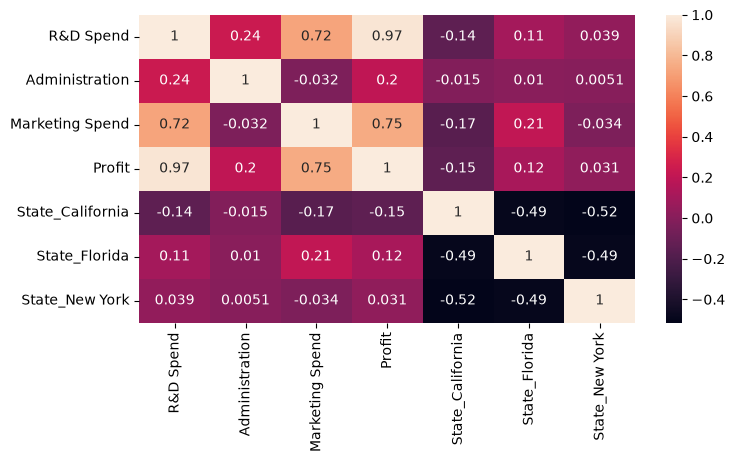

In [24]:
plt.figure(figsize=(8,4))
sn.heatmap(startups.corr(),annot = True)

# 檢視相關係數


In [25]:
startups.corr()

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
R&D Spend,1.000000,0.241955,0.724248,0.972900,-0.143165,0.105711,0.039068
Administration,0.241955,1.000000,-0.032154,0.200717,-0.015478,0.010493,0.005145
Marketing Spend,0.724248,-0.032154,1.000000,0.747766,-0.168875,0.205685,-0.033670
Profit,0.972900,0.200717,0.747766,1.000000,-0.145837,0.116244,0.031368
State_California,-0.143165,-0.015478,-0.168875,-0.145837,1.000000,-0.492366,-0.515152
State_Florida,0.105711,0.010493,0.205685,0.116244,-0.492366,1.000000,-0.492366
State_New York,0.039068,0.005145,-0.033670,0.031368,-0.515152,-0.492366,1.000000


### 觀察結果


1. 研發支出與行銷支出的相關係數約為 0.70，呈正相關。
2. 利潤與研發支出的相關係數約為 0.972，呈高度正相關。
3. 行政支出與研發支出的相關係數約為 0.24，正相關程度較弱。
4. 行政支出與行銷支出的相關係數約為 −0.03，接近沒有線性相關。
5. 加州、佛羅里達州及紐約州的指標欄位，與利潤的相關係數都接近 0，線性相關程度較弱。


In [26]:
startups.rename(columns={'Marketing Spend':'Marketing'},inplace=True)

In [27]:
startups.rename(columns={'R&D Spend':'RD'},inplace=True)

In [28]:
startups.rename(columns={'State_New York':'State_NewYork'},inplace=True)

In [29]:
startups.head()

,RD,Administration,Marketing,Profit,State_California,State_Florida,State_NewYork
0,165349.20,136897.80,471784.10,192261.83,False,False,True
1,162597.70,151377.59,443898.53,191792.06,True,False,False
2,153441.51,101145.55,407934.54,191050.39,False,True,False
3,144372.41,118671.85,383199.62,182901.99,False,False,True
4,142107.34,91391.77,366168.42,166187.94,False,True,False


各欄位的數值尺度不同：支出與利潤是金額，州別指標則表示是否屬於該州。以下使用 `StandardScaler` 對所有欄位進行標準化，包含目標變數 `Profit`。後續預測時，輸入必須使用相同尺度，輸出也必須轉回原始金額。標準化是本範例的處理方式，並非使用獨熱編碼後的必要步驟。


In [30]:
std = StandardScaler()
startup_std = std.fit_transform(startups)
startup_std = pd.DataFrame(startup_std, columns = startups.columns)

In [31]:
startup_std.head()

,RD,Administration,Marketing,Profit,State_California,State_Florida,State_NewYork
0,2.016411,0.560753,2.153943,2.011203,-0.717741,-0.685994,1.393261
1,1.955860,1.082807,1.923600,1.999430,1.393261,-0.685994,-0.717741
2,1.754364,-0.728257,1.626528,1.980842,-0.717741,1.457738,-0.717741
3,1.554784,-0.096365,1.422210,1.776627,-0.717741,-0.685994,1.393261
4,1.504937,-1.079919,1.281528,1.357740,-0.717741,1.457738,-0.717741


# 建立線性迴歸模型


In [32]:
model = smf.ols('Profit~RD+Administration+Marketing+State_California+State_Florida+State_NewYork',data=startup_std).fit()

/tmp/ipykernel_579838/1998535554.py:1: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = smf.ols('Profit~RD+Administration+Marketing+State_California+State_Florida+State_NewYork',data=startup_std).fit()


In [33]:
model.params

Intercept          -5.551115e-16
RD                  9.179307e-01
Administration     -1.877136e-02
Marketing           8.185781e-02
State_California   -6.031706e-04
State_Florida       1.730042e-03
State_NewYork      -1.100457e-03
dtype: float64

# 檢視 t 統計量與 p 值


In [34]:
print(model.tvalues, '\n', model.pvalues)

Intercept          -1.659260e-14
RD                  1.736858e+01
Administration     -5.170116e-01
Marketing           1.573889e+00
State_California   -2.676515e-02
State_Florida       7.490466e-02
State_NewYork      -4.931619e-02
dtype: float64 
 Intercept           1.000000e+00
RD                  2.578772e-21
Administration      6.077373e-01
Marketing           1.226769e-01
State_California    9.787681e-01
State_Florida       9.406301e-01
State_NewYork       9.608905e-01
dtype: float64


# 檢視決定係數 R²


In [35]:
(model.rsquared,model.rsquared_adj)

(np.float64(0.9507524843355148), np.float64(0.945156175737278))

In [36]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Profit   R-squared:                       0.951
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     169.9
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.34e-27
Time:                        15:18:05   Log-Likelihood:                 4.3255
No. Observations:                  50   AIC:                             3.349
Df Residuals:                      44   BIC:                             14.82
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept        -5.551e-16      0.033  -1.66e-14      1.000      -0.067       0.067
RD                   0.9179      0.053     17.369      0.000       0.811       1.024
Administration      -0.0188      0.036     -0.517      0.608      -0.092       0.054
Marketing            0.0819      0.052      1.574      0.123      -0.023       0.187
State_California    -0.0006      0.023     -0.027      0.979      -0.046       0.045
State_Florida        0.0017      0.023      0.075      0.941      -0.045       0.048
State_NewYork       -0.0011      0.022     -0.049      0.961      -0.046       0.044
==============================================================================
Omnibus:                       14.782   Durbin-Watson:                   1.283
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               21.266
Skew:                          -0.948   Prob(JB):                     2.41e-05
Kurtosis:                       5.572   Cond. No.                     9.63e+15
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 1.06e-30. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

上表中，行政支出、行銷支出與各州別指標的 p 值皆大於 0.05。不過，模型同時包含截距與全部 3 個州別指標，存在完全共線性，各州別係數無法唯一決定，解讀時需注意此限制。

以下分別以單一變數建立簡單線性迴歸模型，觀察它們與利潤的關係及 p 值。


### 利潤與行政支出的簡單線性迴歸


In [37]:
model_ad = smf.ols('Profit~Administration',data=startup_std).fit()

In [38]:
model_ad.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Profit   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     2.015
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.162
Time:                        15:18:05   Log-Likelihood:                -69.919
No. Observations:                  50   AIC:                             143.8
Df Residuals:                      48   BIC:                             147.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept      -5.274e-16      0.141  -3.73e-15      1.000      -0.284       0.284
Administration     0.2007      0.141      1.419      0.162      -0.084       0.485
==============================================================================
Omnibus:                        0.126   Durbin-Watson:                   0.099
Prob(Omnibus):                  0.939   Jarque-Bera (JB):                0.110
Skew:                           0.093   Prob(JB):                        0.947
Kurtosis:                       2.866   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

行政支出的 p 值約為 0.162，大於 0.05；它與利潤的相關係數約為 0.20。以本資料及模型而言，尚無足夠證據支持兩者具有顯著的線性關係，但這不等於行政支出完全沒有預測價值。


### 利潤與行銷支出的簡單線性迴歸


In [39]:
model_mkt = smf.ols('Profit~Marketing',data=startup_std).fit()

In [40]:
model_mkt.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Profit   R-squared:                       0.559
Model:                            OLS   Adj. R-squared:                  0.550
Method:                 Least Squares   F-statistic:                     60.88
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           4.38e-10
Time:                        15:18:05   Log-Likelihood:                -50.470
No. Observations:                  50   AIC:                             104.9
Df Residuals:                      48   BIC:                             108.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -5.274e-16      0.096   -5.5e-15      1.000      -0.193       0.193
Marketing      0.7478      0.096      7.803      0.000       0.555       0.940
==============================================================================
Omnibus:                        4.420   Durbin-Watson:                   1.178
Prob(Omnibus):                  0.110   Jarque-Bera (JB):                3.882
Skew:                          -0.336   Prob(JB):                        0.144
Kurtosis:                       4.188   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

行銷支出的 p 值小於 0.05，與利潤的相關係數約為 0.75，表示在單一變數模型中，兩者具有顯著的線性關係。表格若將 p 值顯示為 0.000，是四捨五入的結果，不代表精確等於零。

在前面的多變量模型中，行銷支出的 p 值約為 0.123。加入其他變數後，行銷支出所提供的額外資訊可能減少；以下使用變異數膨脹因子（VIF）進一步檢查共線性。


### 利潤與研發支出的簡單線性迴歸


In [41]:
model_rd = smf.ols('Profit~RD',data=startup_std).fit()

In [42]:
model_rd.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Profit   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     849.8
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           3.50e-32
Time:                        15:18:05   Log-Likelihood:                 2.2714
No. Observations:                  50   AIC:                           -0.5428
Df Residuals:                      48   BIC:                             3.281
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -5.274e-16      0.033  -1.58e-14      1.000      -0.067       0.067
RD             0.9729      0.033     29.151      0.000       0.906       1.040
==============================================================================
Omnibus:                       13.727   Durbin-Watson:                   1.116
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               18.536
Skew:                          -0.911   Prob(JB):                     9.44e-05
Kurtosis:                       5.361   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

研發支出的 p 值小於 0.05，與利潤的相關係數約為 0.97，表示兩者具有顯著且高度的正向線性關係。表格顯示的 0.000 為四捨五入結果，不代表 p 值精確等於零。


### 利潤與加州指標的簡單線性迴歸


In [43]:
model_sc = smf.ols('Profit~State_California',data=startup_std).fit()

In [44]:
model_sc.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Profit   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.043
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.312
Time:                        15:18:05   Log-Likelihood:                -70.409
No. Observations:                  50   AIC:                             144.8
Df Residuals:                      48   BIC:                             148.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept        -5.274e-16      0.143  -3.69e-15      1.000      -0.287       0.287
State_California    -0.1458      0.143     -1.021      0.312      -0.433       0.141
==============================================================================
Omnibus:                        0.079   Durbin-Watson:                   0.073
Prob(Omnibus):                  0.961   Jarque-Bera (JB):                0.190
Skew:                           0.087   Prob(JB):                        0.909
Kurtosis:                       2.753   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

加州指標（`State_California`）的 p 值約為 0.312，大於 0.05；與利潤的相關係數約為 −0.15。以本資料而言，尚無足夠證據支持兩者具有顯著的線性關係。


### 利潤與佛羅里達州指標的簡單線性迴歸


In [45]:
model_sf = smf.ols('Profit~State_Florida',data=startup_std).fit()

In [46]:
model_sf.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Profit   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                 -0.007
Method:                 Least Squares   F-statistic:                    0.6575
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.421
Time:                        15:18:05   Log-Likelihood:                -70.607
No. Observations:                  50   AIC:                             145.2
Df Residuals:                      48   BIC:                             149.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -5.274e-16      0.143  -3.68e-15      1.000      -0.288       0.288
State_Florida     0.1162      0.143      0.811      0.421      -0.172       0.404
==============================================================================
Omnibus:                        0.077   Durbin-Watson:                   0.058
Prob(Omnibus):                  0.962   Jarque-Bera (JB):                0.123
Skew:                           0.080   Prob(JB):                        0.940
Kurtosis:                       2.817   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

佛羅里達州指標（`State_Florida`）的 p 值約為 0.421，大於 0.05；與利潤的相關係數約為 0.12。以本資料而言，尚無足夠證據支持兩者具有顯著的線性關係。


### 利潤與紐約州指標的簡單線性迴歸


In [47]:
model_sny = smf.ols('Profit~State_NewYork',data=startup_std).fit()

In [48]:
model_sny.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Profit   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.020
Method:                 Least Squares   F-statistic:                   0.04727
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.829
Time:                        15:18:05   Log-Likelihood:                -70.922
No. Observations:                  50   AIC:                             145.8
Df Residuals:                      48   BIC:                             149.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -5.274e-16      0.144  -3.66e-15      1.000      -0.290       0.290
State_NewYork     0.0314      0.144      0.217      0.829      -0.259       0.321
==============================================================================
Omnibus:                        0.011   Durbin-Watson:                   0.021
Prob(Omnibus):                  0.994   Jarque-Bera (JB):                0.082
Skew:                           0.022   Prob(JB):                        0.960
Kurtosis:                       2.807   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

紐約州指標（`State_NewYork`）的 p 值約為 0.829，大於 0.05；與利潤的相關係數約為 0.031。以本資料而言，尚無足夠證據支持兩者具有顯著的線性關係。


# 使用變異數膨脹因子檢查共線性


In [49]:
def calculate_vif(r_squared):
    # 完全共線性會使 R² 等於 1，此時 VIF 為無限大。
    return np.inf if np.isclose(r_squared, 1.0) else 1.0 / (1.0 - r_squared)

rsq_rd = smf.ols('RD~Administration+Marketing+State_California+State_Florida+State_NewYork',data=startup_std).fit().rsquared  
vif_rd = calculate_vif(rsq_rd)

rsq_ad = smf.ols('Administration~RD+Marketing+State_California+State_Florida+State_NewYork',data=startup_std).fit().rsquared  
vif_ad = calculate_vif(rsq_ad)

rsq_mkt = smf.ols('Marketing~RD+Administration+State_California+State_Florida+State_NewYork',data=startup_std).fit().rsquared  
vif_mkt = calculate_vif(rsq_mkt) 

rsq_sc = smf.ols('State_California~RD+Administration+Marketing+State_Florida+State_NewYork',data=startup_std).fit().rsquared  
vif_sc = calculate_vif(rsq_sc)

rsq_sf = smf.ols('State_Florida~RD+Administration+Marketing+State_California+State_NewYork',data=startup_std).fit().rsquared  
vif_sf = calculate_vif(rsq_sf)

rsq_sny = smf.ols('State_NewYork~RD+Administration+Marketing+State_California+State_Florida',data=startup_std).fit().rsquared  
vif_sny = calculate_vif(rsq_sny)


# 將各變數的 VIF 整理成資料表。
d1 = {'Features':['RD','Administration','Marketing','State_California','State_Florida','State_NewYork'],'VIF':[vif_rd,vif_ad,vif_mkt,vif_sc,vif_sf,vif_sny]}
Vif_frame = pd.DataFrame(d1)  
Vif_frame

/tmp/ipykernel_579838/2943677177.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  rsq_rd = smf.ols('RD~Administration+Marketing+State_California+State_Florida+State_NewYork',data=startup_std).fit().rsquared
/tmp/ipykernel_579838/2943677177.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  rsq_ad = smf.ols('Administration~RD+Marketing+State_California+State_Florida+State_NewYork',data=startup_std).fit().rsquared
/tmp/ipykernel_579838/2943677177.py:11: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  rsq_mkt = smf.ols('Marketing~RD+Administration+State_California+State_Florida+State_NewYork',data=startup_std).fit().rsquared


,Features,VIF
0,RD,2.495511
1,Administration,1.177766
2,Marketing,2.416797
3,State_California,inf
4,State_Florida,inf
5,State_NewYork,inf


州別指標的 VIF 為無限大，表示存在完全共線性：模型同時納入截距與全部 3 個州別指標，而這些指標彼此存在精確的線性關係，因此係數無法唯一決定。下方最終模型僅使用研發支出（`RD`）。


上述單一變數模型中，州別與行政支出未達 0.05 的顯著水準；VIF 則用來檢查共線性，不能直接判定變數是否具有預測價值。以下先以研發支出與行銷支出建立模型，繼續比較。


### 利潤、研發支出與行銷支出的多元線性迴歸


In [50]:
model_rd_m = smf.ols('Profit~RD+Marketing',data=startup_std).fit()

In [51]:
model_rd_m.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Profit   R-squared:                       0.950
Model:                            OLS   Adj. R-squared:                  0.948
Method:                 Least Squares   F-statistic:                     450.8
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.16e-31
Time:                        15:18:05   Log-Likelihood:                 4.1726
No. Observations:                  50   AIC:                            -2.345
Df Residuals:                      47   BIC:                             3.391
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -5.274e-16      0.032  -1.62e-14      1.000      -0.065       0.065
RD             0.9072      0.047     19.266      0.000       0.812       1.002
Marketing      0.0907      0.047      1.927      0.060      -0.004       0.185
==============================================================================
Omnibus:                       14.677   Durbin-Watson:                   1.257
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               21.161
Skew:                          -0.939   Prob(JB):                     2.54e-05
Kurtosis:                       5.575   Cond. No.                         2.50
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [52]:
(model_mkt.rsquared,model_mkt.aic)

(np.float64(0.5591535746115515), np.float64(104.94091802371327))

In [53]:
(model_rd.rsquared,model_rd.aic)

(np.float64(0.9465353160804392), np.float64(-0.5428445147423275))

比較分別使用行銷支出及研發支出的單一變數模型，研發支出模型的 R² 較高、赤池資訊量準則（AIC）較低，因此本範例選擇僅使用研發支出的模型進行後續分析。這項比較不代表研發支出已涵蓋所有預測資訊。


In [54]:
(model_rd.rsquared,model_rd.rsquared_adj)

(np.float64(0.9465353160804392), np.float64(0.9454214684987816))

# 使用殘差分析檢查模型


### 使用 Q–Q 圖檢查殘差的常態性


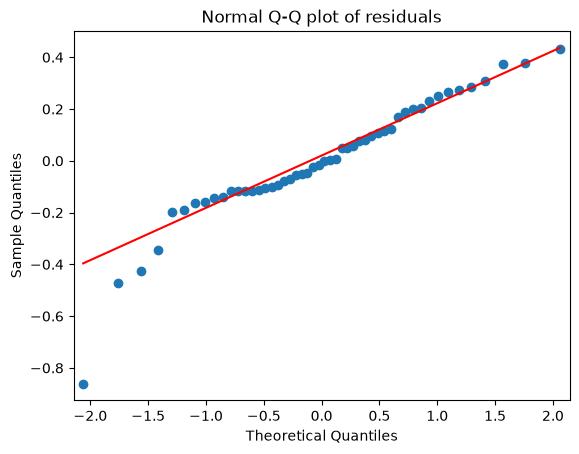

In [55]:
import statsmodels.api as sm
qqplot=sm.qqplot(model_rd.resid,line='q') 
plt.title("Normal Q-Q plot of residuals")
plt.show()

In [56]:
list(np.where(model_rd.resid<-0.8))

[array([49])]

圖中大部分資料點接近參考直線，但索引 49（第 50 筆）的資料點偏離較明顯。以下將使用庫克距離，評估這筆資料對模型估計的影響。


### 使用殘差圖檢查等變異性


In [57]:
def get_standardized_values( vals ):
    return (vals - vals.mean())/vals.std()

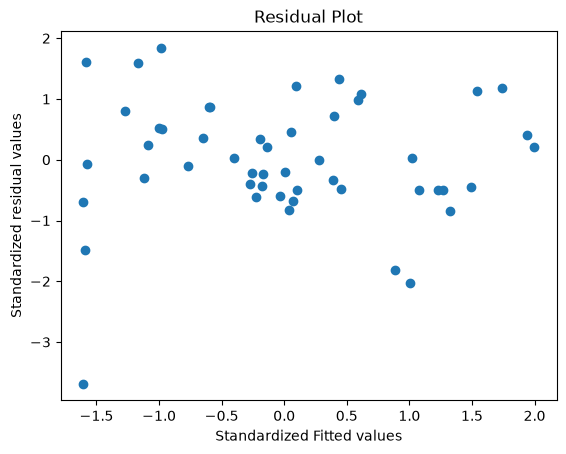

In [58]:
plt.scatter(get_standardized_values(model_rd.fittedvalues),
            get_standardized_values(model_rd.resid))

plt.title('Residual Plot')
plt.xlabel('Standardized Fitted values')
plt.ylabel('Standardized residual values')
plt.show()

殘差圖中未見明顯的規律，可作為線性關係與等變異假設的初步參考；這不代表誤差變異為零，也不能只靠此圖確認所有模型假設。


### 殘差與解釋變數的關係


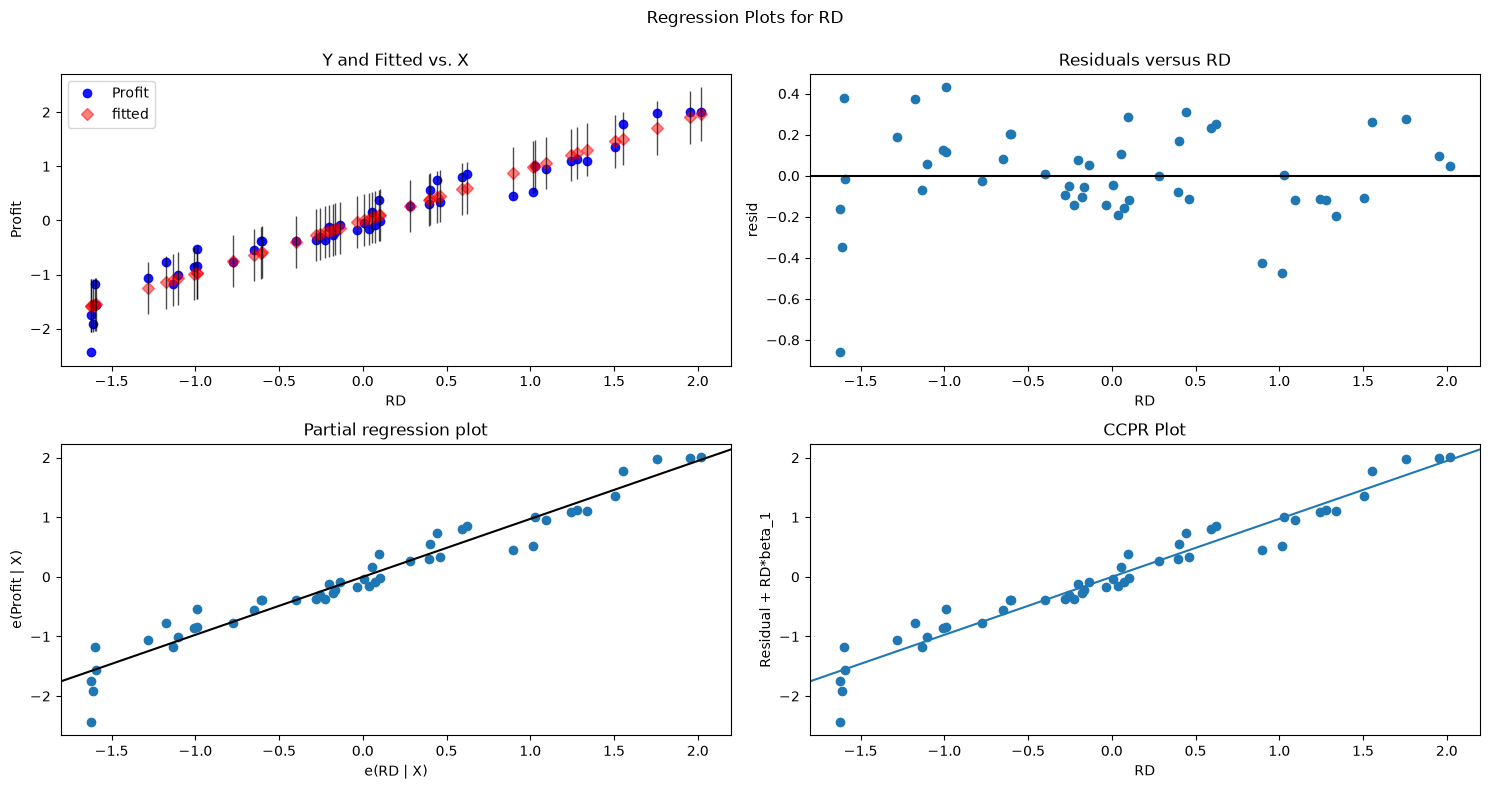

In [59]:
fig = plt.figure(figsize=(15,8))
fig = sm.graphics.plot_regress_exog(model_rd, "RD", fig=fig)
plt.show()

殘差與研發支出的關係圖中未見明顯規律，可作為線性模型是否適合的初步參考；這不代表模型沒有誤差或誤差變異。


# 觀測值影響診斷


## 使用庫克距離找出高影響觀測值


In [60]:
model_influence = model_rd.get_influence()
(c, _) = model_influence.cooks_distance

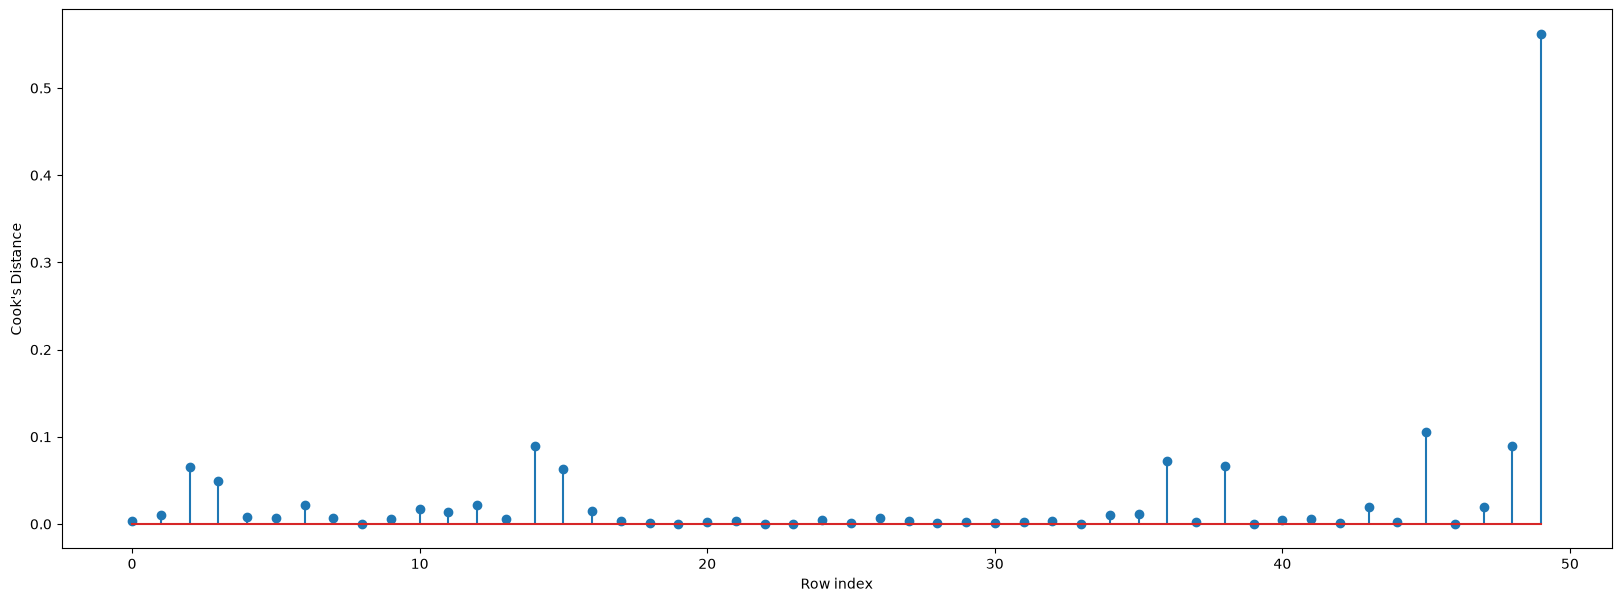

In [61]:
# 繪製每筆觀測值的庫克距離。
fig, ax = plt.subplots(figsize=(20, 7))
ax.stem(np.arange(len(c)), np.round(c, 3))
ax.set_xlabel('Row index')
ax.set_ylabel("Cook's Distance")
plt.show()


In [62]:
(np.argmax(c),np.max(c))

(np.int64(49), np.float64(0.5620610259264278))

索引 49（第 50 筆）的庫克距離最大，表示它對模型估計的影響較大。以下示範移除這筆資料後重新建模；高影響值不一定是錯誤資料，實際分析應先確認原因，也不能將移除後的擬合改善直接視為預測能力提升。


### 移除高影響觀測值後重新建模


In [63]:
startup=startup_std.drop(startup_std.index[[49]],axis=0).reset_index()

In [64]:
startup.shape

(49, 8)

In [65]:
startup.head()

,index,RD,Administration,Marketing,Profit,State_California,State_Florida,State_NewYork
0,0,2.016411,0.560753,2.153943,2.011203,-0.717741,-0.685994,1.393261
1,1,1.955860,1.082807,1.923600,1.999430,1.393261,-0.685994,-0.717741
2,2,1.754364,-0.728257,1.626528,1.980842,-0.717741,1.457738,-0.717741
3,3,1.554784,-0.096365,1.422210,1.776627,-0.717741,-0.685994,1.393261
4,4,1.504937,-1.079919,1.281528,1.357740,-0.717741,1.457738,-0.717741


## 建立最終模型


In [66]:
final_model= smf.ols('Profit~RD',data = startup).fit()

In [67]:
(final_model.rsquared,final_model.rsquared_adj)

(np.float64(0.9573395972488337), np.float64(0.9564319291051918))

最終模型在建模資料上的調整後 R² 約為 0.956，表示對這批資料的擬合程度；它不是對未見資料的預測準確率。


## 預測新資料


In [68]:
# 使用建模時的平均數與標準差，將輸入的研發支出標準化。
rd_index = startups.columns.get_loc('RD')
profit_index = startups.columns.get_loc('Profit')
new_data = pd.DataFrame({'RD': [(100000 - std.mean_[rd_index]) / std.scale_[rd_index]]})


In [69]:
# 將標準化的預測值轉回利潤的原始金額單位。
predicted_profit_std = final_model.predict(new_data)
predicted_profit = predicted_profit_std * std.scale_[profit_index] + std.mean_[profit_index]
predicted_profit.rename('Predicted Profit')


0    134507.814221
Name: Predicted Profit, dtype: float64

上方結果為研發支出 100,000 時的預測利潤，已由標準化尺度轉回原始金額單位。
